# 07 · Schrödinger (1926)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/07_schrodinger.ipynb)

Lượng tử hoá xuất hiện khi tìm nghiệm tắt dần của phương trình Schrödinger. Kiểm tra giếng hữu hạn, hydro, xuyên hầm và một mô hình đồ chơi gợi ý tưởng Gamow (1928). Chạy từ trên xuống; không cần dữ liệu bên ngoài.
*Quantisation emerges from the decaying solutions of Schrödinger's equation. Check a finite well, hydrogen, tunnelling, and a toy model illustrating Gamow's 1928 idea. Run top to bottom; no external data are needed.*

Đơn vị: electron, nm, eV, fs. *Units: electron, nm, eV, fs.*

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import trapezoid
from scipy.sparse import diags
from scipy.sparse.linalg import splu

C = 0.0380998212  # hbar^2 / (2 m_e), eV nm^2
HBAR = 0.6582119569  # eV fs
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.2})

def numerov(E, potential, x0, x1, steps):
    x = np.linspace(x0, x1, steps + 1)
    q = (x[1] - x[0])**2 * (potential(x) - E) / (12 * C)
    psi = np.zeros_like(x)
    psi[1] = 1e-6
    for i in range(1, steps):
        psi[i + 1] = (2 * (1 + 5*q[i]) * psi[i] - (1 - q[i-1]) * psi[i-1]) / (1 - q[i+1])
    return x, psi

def well_potential(x, V0=4, width=1):
    return np.where(np.abs(x) < width/2, 0.0, V0)


## 1. Giếng hữu hạn / Finite well

Đặt $a=w/2$, $z=ka$, $z_0=a\sqrt{V_0/C}$. Ghép liên tục hàm sóng và đạo hàm ở hai vách cho:
*With the definitions above, continuity of the wave and its derivative at each wall gives:*

$$z\tan z=\sqrt{z_0^2-z^2}\quad\text{(even)},\qquad -z\cot z=\sqrt{z_0^2-z^2}\quad\text{(odd)},\qquad E=C(z/a)^2.$$

Tách từng nhánh giữa các cực của tan/cot để tránh nhận cực nhầm là nghiệm. Numerov độc lập quét năng lượng, rồi chia đôi theo dấu đuôi sóng ở biên phải. Hai vách nằm giữa các điểm lưới; biên xa thay đuôi vô hạn bằng điều kiện Dirichlet.
*Separate the branches between tan/cot poles so poles are not mistaken for roots. Independent Numerov shooting scans energy and bisects the right-tail sign. Walls sit between grid points; distant Dirichlet boundaries approximate the infinite tails.*

 n    Analytic (eV)   Numerov (eV)    Difference (eV)
 1     0.262271561    0.262271381   -1.801e-07
 2     1.036244896    1.036244275   -6.208e-07
 3     2.269881379    2.269880396   -9.829e-07
 4     3.753886272    3.753887057   +7.850e-07
V0= 400 eV: ground=0.361767358 eV, relative difference=-3.7930%
V0=1600 eV: ground=0.368796159 eV, relative difference=-1.9238%


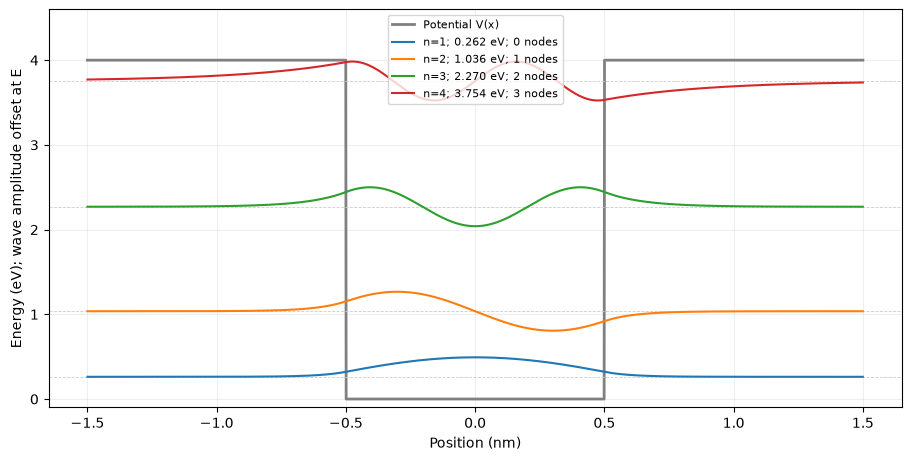

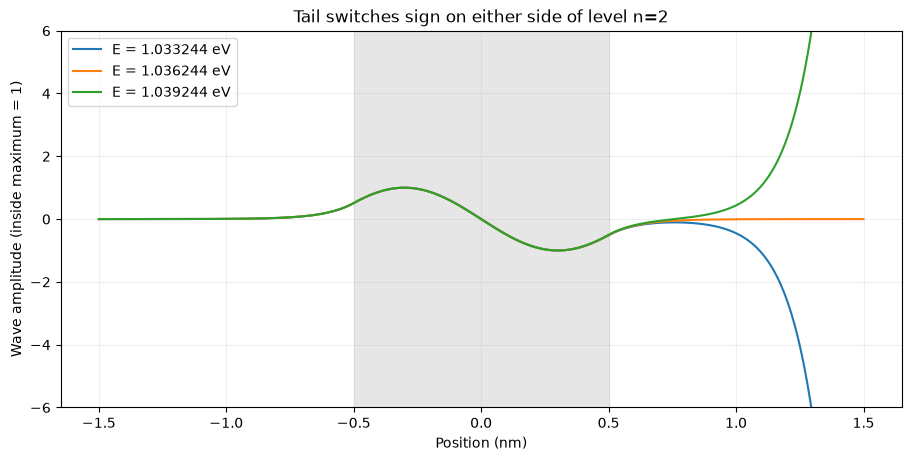

In [2]:
def analytic_levels(V0, width):
    a = width / 2
    z0 = a * np.sqrt(V0 / C)
    levels = []
    for j in range(int(2*z0/np.pi) + 1):
        lo, hi = j*np.pi/2 + 1e-9, min((j+1)*np.pi/2 - 1e-9, z0 - 1e-9)
        if lo >= hi:
            continue
        def condition(z):
            left = z*np.tan(z) if j % 2 == 0 else -z/np.tan(z)
            return left - np.sqrt(z0*z0 - z*z)
        if condition(lo) * condition(hi) < 0:
            levels.append(C * (brentq(condition, lo, hi) / a)**2)
    return np.array(levels)

def shooting_levels(V0, width):
    h = width / 2000
    decay_length = np.sqrt(C / V0)
    tail = min(max(2.5*width, 14*decay_length), 80*decay_length)
    side = 1000 + int(np.ceil(tail / h))
    extent, steps = (side + 0.5)*h, 2*side + 1
    potential = lambda x: well_potential(x, V0, width)
    shot = lambda E: numerov(E, potential, -extent, extent, steps)[1][-1]
    scan = V0 * np.linspace(0, 1, 121)**2 * (1 - 1e-12)
    energies = []
    previous = shot(scan[0])
    for lo, hi in zip(scan[:-1], scan[1:]):
        value = shot(hi)
        if np.sign(previous) != np.sign(value):
            energies.append(brentq(shot, lo, hi, xtol=2e-13))
        previous = value
    return np.array(energies), (extent, steps)

analytic = analytic_levels(4, 1)
levels, (extent, steps) = shooting_levels(4, 1)
print(" n    Analytic (eV)   Numerov (eV)    Difference (eV)")
for n, (a, b) in enumerate(zip(analytic, levels), 1):
    print(f"{n:2d}    {a:12.9f}   {b:12.9f}   {b-a:+.3e}")
assert len(levels) == 4
assert np.allclose(levels, [0.2623, 1.0362, 2.2699, 3.7539], atol=0.002, rtol=0)
assert np.allclose(levels, analytic, atol=2e-6, rtol=0)
# A 400 eV well still differs from infinity by 3.793%; use 1600 eV for 2%.
infinite_ground = np.pi**2 * C
for depth in [400, 1600]:
    ground = analytic_levels(depth, 1)[0]
    print(f"V0={depth:4d} eV: ground={ground:.9f} eV, relative difference={100*(ground/infinite_ground-1):+.4f}%")
assert abs(analytic_levels(1600, 1)[0] / infinite_ground - 1) < 0.02

fig, ax = plt.subplots(layout="constrained")
x_view = np.linspace(-1.5, 1.5, 2000)
ax.plot(x_view, well_potential(x_view), color="0.5", lw=2, label="Potential V(x)")
for n, energy in enumerate(levels, 1):
    x, psi = numerov(energy, well_potential, -extent, extent, steps)
    psi /= np.max(np.abs(psi[np.abs(x) < 0.5]))
    mask = np.abs(x) <= 1.5
    ax.axhline(energy, color="0.8", lw=0.6, ls="--")
    ax.plot(x[mask], energy + 0.23*psi[mask], label=f"n={n}; {energy:.3f} eV; {n-1} nodes")
ax.set(xlabel="Position (nm)", ylabel="Energy (eV); wave amplitude offset at E", ylim=(-0.1, 4.6))
ax.legend(fontsize=8, loc="upper center")
plt.show()

fig, ax = plt.subplots(layout="constrained")
for delta in [-0.003, 0, 0.003]:
    energy = levels[1] + delta
    x, psi = numerov(energy, well_potential, -extent, extent, steps)
    psi /= np.max(np.abs(psi[np.abs(x) < 0.5]))
    mask = np.abs(x) <= 1.5
    ax.plot(x[mask], psi[mask], label=f"E = {energy:.6f} eV")
ax.axvspan(-0.5, 0.5, color="0.9", zorder=-1)
ax.set(xlabel="Position (nm)", ylabel="Wave amplitude (inside maximum = 1)", ylim=(-6, 6), title="Tail switches sign on either side of level n=2")
ax.legend()
plt.show()


## 2. Hydro theo phương trình xuyên tâm / Hydrogen by radial shooting

Với $\ell=0$, đặt $u(r)=rR(r)$:

$$-C u''(r)-\frac{g}{r}u(r)=Eu(r),\quad u(0)=0,\quad u(\infty)=0,\quad g=1.439964548\ \mathrm{eV\,nm}.$$

Tích phân Numerov từ gần gốc, dùng chuỗi $u(r)=r-r^2/a_0+(2/a_0^2-E/C)r^3/6+\cdots$, $a_0=2C/g$. Tìm các đổi dấu ở biên phải. Hạt nhân coi như vô hạn khối lượng: $E_n=-g^2/(4Cn^2)\simeq-13.6/n^2$ eV, trùng các mức Bohr ở [bài 4](../vi/04-bohr.html).
*For s states, shoot the radial equation from its regular series near the origin and locate right-end sign changes. With infinite nuclear mass, the energies recover the Bohr levels from [episode 4](../en/04-bohr.html). The web Bohr model uses reduced mass, differing by about 0.05%.*

In [3]:
g = 1.439964548
bohr_radius = 2*C/g
rydberg = g*g/(4*C)
r_step, r_max = 0.0004, 10.0
r = np.arange(1, int(round(r_max/r_step)) + 1) * r_step
radial_potential = -g/r

def radial_shot(E):
    q = r_step*r_step * (radial_potential - E) / (12*C)
    series = lambda radius: radius * (1 - radius/bohr_radius + (2/bohr_radius**2 - E/C)*radius**2/6)
    u0, u1 = series(r[0]), series(r[1])
    for i in range(1, len(r)-1):
        u2 = (2*(1+5*q[i])*u1 - (1-q[i-1])*u0) / (1-q[i+1])
        u0, u1 = u1, u2
    return u1

scan = np.linspace(-16, -1, 220)
radial_levels = []
previous = radial_shot(scan[0])
for lo, hi in zip(scan[:-1], scan[1:]):
    value = radial_shot(hi)
    if np.sign(previous) != np.sign(value):
        radial_levels.append(brentq(radial_shot, lo, hi, xtol=1e-10))
    previous = value
assert len(radial_levels) == 3
print(" n     Shooting (eV)     -Ry/n^2 (eV)     Relative error")
for n, energy in enumerate(radial_levels, 1):
    exact = -rydberg/n**2
    print(f"{n:2d}    {energy:14.8f}    {exact:14.8f}    {energy/exact-1:+.3e}")
    assert abs(energy/exact-1) < 0.0002
print(f"a0 = {bohr_radius:.9f} nm; Ry = {rydberg:.9f} eV")


 n     Shooting (eV)     -Ry/n^2 (eV)     Relative error
 1      -13.60569270      -13.60569311    -3.014e-08
 2       -3.40142325       -3.40142328    -7.559e-09
 3       -1.51174367       -1.51174368    -4.109e-09
a0 = 0.052917721 nm; Ry = 13.605693112 eV


## 3. Xuyên hầm / Tunnelling

Với rào chữ nhật, $E<V_0$:

$$T(E)=\left[1+\frac{V_0^2\sinh^2(w\sqrt{(V_0-E)/C})}{4E(V_0-E)}\right]^{-1}.$$

Với $E>V_0$, thay sinh bằng sin và $V_0-E$ bằng $E-V_0$. Tại $E=V_0$, $T=[1+V_0w^2/(4C)]^{-1}$.
*Above the barrier, replace sinh by sin and reverse the gap. The threshold has the finite limit shown above.*

Crank–Nicolson: $(I+i\Delta tH/2\hbar)\psi_{t+\Delta t}=(I-i\Delta tH/2\hbar)\psi_t$. Ma trận $H$ thực đối xứng nên bước thời gian bảo toàn chuẩn. Gói Gaussian có $\sigma_x=2.5$ nm và $\sigma_k=1/(2\sigma_x)$; đối chiếu tích phân truyền qua với $\langle T\rangle=\int|\tilde\psi(k)|^2T(Ck^2)\,dk$, không chỉ $T(E_0)$.
*The Hermitian grid Hamiltonian makes Crank–Nicolson norm preserving. Compare the packet transmission to the plane-wave formula averaged over its momentum distribution, rather than only the central energy.*

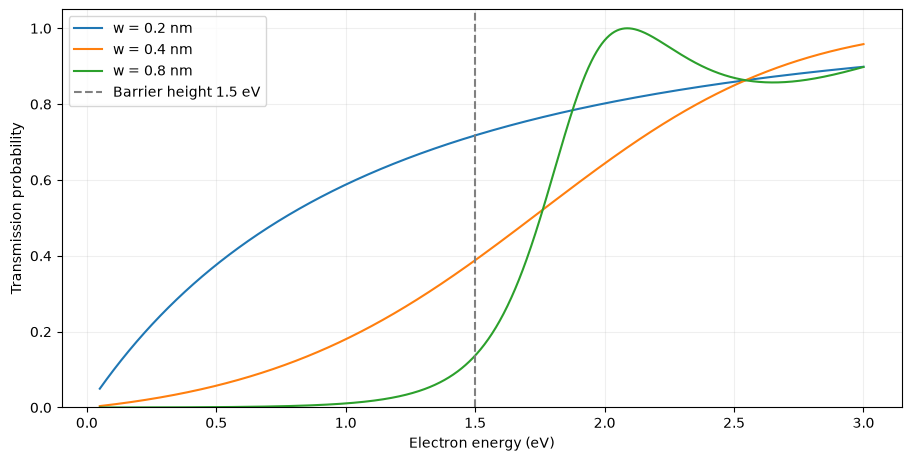

Final time: 69.84 fs; norm drift: +2.249e-13
Transmitted: 0.181660; reflected: 0.818340; in barrier: 9.356e-13
Plane wave at E0: 0.180025; momentum-averaged: 0.181638
Packet vs averaged continuum formula: +0.000022


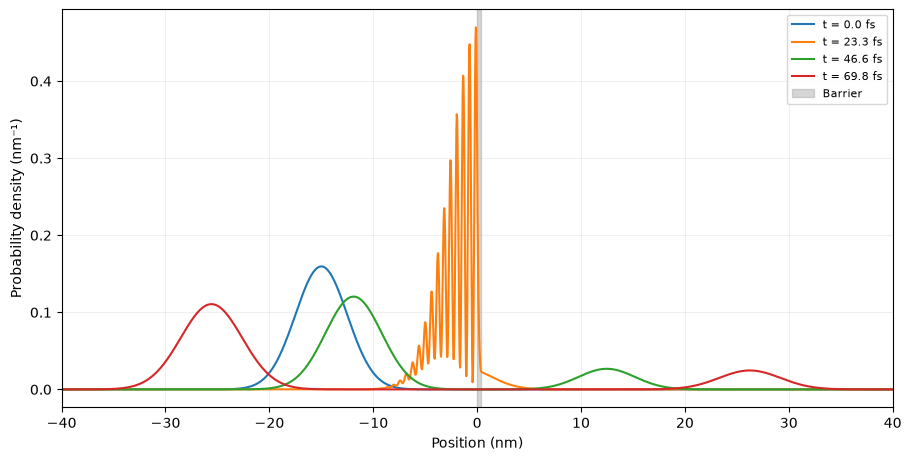

In [4]:
def transmission(energy, V0, width):
    energy = np.asarray(energy, dtype=float)
    result = np.zeros_like(energy)
    if V0 == 0 or width == 0:
        return np.ones_like(energy)
    at = (energy > 0) & (np.abs(energy - V0) < 1e-9)
    result[at] = 1 / (1 + V0*width*width/(4*C))
    for below in [True, False]:
        mask = (energy > 0) & ~at & ((energy < V0) if below else (energy > V0))
        E = energy[mask]
        gap = np.abs(E - V0)
        phase = width*np.sqrt(gap/C)
        factor = np.sinh(phase) if below else np.sin(phase)
        result[mask] = 1/(1 + V0*V0*factor*factor/(4*E*gap))
    return result

energy_grid = np.linspace(0.05, 3.0, 1200)
fig, ax = plt.subplots(layout="constrained")
for width in [0.2, 0.4, 0.8]:
    ax.plot(energy_grid, transmission(energy_grid, 1.5, width), label=f"w = {width} nm")
ax.axvline(1.5, color="0.5", ls="--", label="Barrier height 1.5 eV")
ax.set(xlabel="Electron energy (eV)", ylabel="Transmission probability", ylim=(0, 1.05))
ax.legend()
plt.show()
assert np.isclose(transmission(1, 1.5, 0.4), 0.1800, atol=0.001)
assert abs(transmission(1.5-1e-6, 1.5, 0.4) - transmission(1.5+1e-6, 1.5, 0.4)) < 1e-4

# Match the browser grid. Use cell-averaged edge potentials to preserve V0*w.
dx, dt, V0, width, E0, sigma = 0.04, 0.04, 1.5, 0.4, 1.0, 2.5
x = np.linspace(-40, 40, 2001)
k0 = np.sqrt(E0/C)
psi = np.exp(-(x+15)**2/(4*sigma*sigma)) * np.exp(1j*k0*x)
psi[[0, -1]] = 0
psi /= np.sqrt(np.sum(np.abs(psi)**2)*dx)
V = V0 * np.maximum(0, np.minimum(x+dx/2, width) - np.maximum(x-dx/2, 0)) / dx
size = len(x)-2
H = diags([-C/dx**2*np.ones(size-1), 2*C/dx**2+V[1:-1], -C/dx**2*np.ones(size-1)], [-1, 0, 1], format="csc")
identity = diags(np.ones(size), format="csc")
A = identity + 1j*dt/(2*HBAR)*H
B = identity - 1j*dt/(2*HBAR)*H
solver = splu(A)
velocity = 2*C*k0/HBAR
steps = int(np.ceil(((41+width)/velocity)/dt))
snapshots = {0: np.abs(psi)**2}
initial_norm = np.sum(np.abs(psi)**2)*dx
for step in range(1, steps+1):
    psi[1:-1] = solver.solve(B @ psi[1:-1])
    if step in [steps//3, 2*steps//3, steps]:
        snapshots[step] = np.abs(psi)**2
norm = np.sum(np.abs(psi)**2)*dx
transmitted = np.sum(np.abs(psi[x > width])**2)*dx
reflected = np.sum(np.abs(psi[x < 0])**2)*dx
k = np.linspace(k0-8/(2*sigma), k0+8/(2*sigma), 12001)
weights = np.exp(-2*sigma*sigma*(k-k0)**2)
averaged = trapezoid(weights*transmission(C*k*k, V0, width), k) / trapezoid(weights, k)
print(f"Final time: {steps*dt:.2f} fs; norm drift: {norm-initial_norm:+.3e}")
print(f"Transmitted: {transmitted:.6f}; reflected: {reflected:.6f}; in barrier: {norm-transmitted-reflected:.3e}")
print(f"Plane wave at E0: {float(transmission(E0, V0, width)):.6f}; momentum-averaged: {averaged:.6f}")
print(f"Packet vs averaged continuum formula: {transmitted-averaged:+.6f}")
assert abs(norm-initial_norm) < 1e-6
# Finite dx, cell-averaged walls and the energy spread give a small grid error.
assert abs(transmitted-averaged) < 0.015

fig, ax = plt.subplots(layout="constrained")
for step, density in snapshots.items():
    ax.plot(x, density, label=f"t = {step*dt:.1f} fs")
ax.axvspan(0, width, color="0.6", alpha=0.4, label="Barrier")
ax.set(xlabel="Position (nm)", ylabel="Probability density (nm⁻¹)", xlim=(-40, 40))
ax.legend(fontsize=8)
plt.show()


## 4. Gamow (1928): mô hình đồ chơi / A historical toy

Một dòng: $\log T\simeq\mathrm{const}-2w\sqrt{(V_0-E)/C}$. Xác suất xuyên hầm phụ thuộc theo hàm mũ: thay đổi năng lượng nhỏ có thể đổi thời gian chờ thoát ra rất nhiều lần. Nếu tần suất đập vào rào giữ nguyên, thời gian bán rã tỉ lệ với $1/T$.
*One line: tunnelling probability depends exponentially on barrier thickness and on the energy-dependent decay constant. With a fixed attempt rate, a toy half-life is proportional to $1/T$.*

Đây chỉ là minh hoạ bằng electron qua rào chữ nhật, **không** là mô hình số cho phân rã alpha: khối lượng alpha và rào Coulomb khác. Không dùng dữ liệu hạt nhân.
*This electron/rectangular-barrier toy illustrates the exponential mechanism, not quantitative alpha decay: an alpha particle has a different mass and faces a Coulomb barrier. No nuclear data are used.*

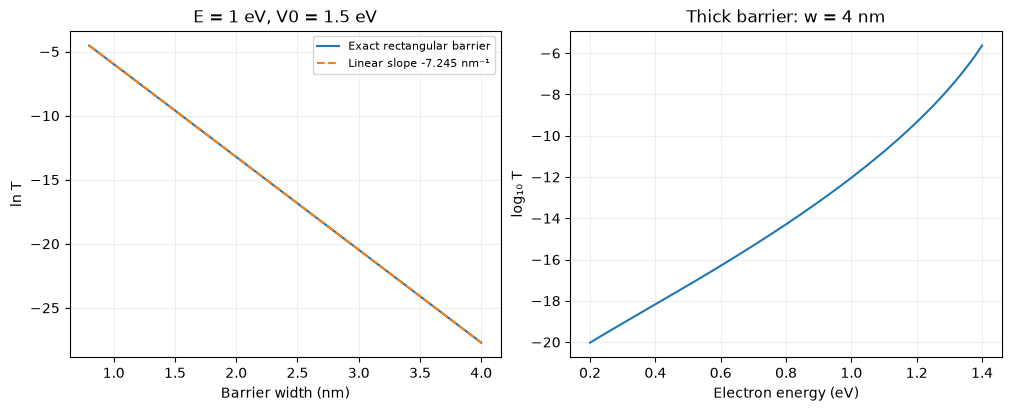

Fitted d(ln T)/dw = -7.244886 nm^-1; asymptotic prediction = -7.245253 nm^-1
All finite-well, hydrogen, tunnelling and norm checks passed.


In [5]:
widths = np.linspace(0.8, 4, 200)
log_T = np.log([float(transmission(1.0, 1.5, value)) for value in widths])
slope, intercept = np.polyfit(widths, log_T, 1)
asymptotic_slope = -2*np.sqrt((1.5-1.0)/C)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(widths, log_T, label="Exact rectangular barrier")
axes[0].plot(widths, slope*widths+intercept, "--", label=f"Linear slope {slope:.3f} nm⁻¹")
axes[0].set(xlabel="Barrier width (nm)", ylabel="ln T", title="E = 1 eV, V0 = 1.5 eV")
axes[0].legend(fontsize=8)
energy_grid = np.linspace(0.2, 1.4, 400)
axes[1].plot(energy_grid, np.log10(transmission(energy_grid, 1.5, 4)))
axes[1].set(xlabel="Electron energy (eV)", ylabel="log₁₀ T", title="Thick barrier: w = 4 nm")
plt.show()
print(f"Fitted d(ln T)/dw = {slope:.6f} nm^-1; asymptotic prediction = {asymptotic_slope:.6f} nm^-1")
assert abs(slope/asymptotic_slope - 1) < 0.002
print("All finite-well, hydrogen, tunnelling and norm checks passed.")
